In [1]:
# Celda 1 — Bootstrap: conecta el notebook con Django para poder usar los modelos y la base de datos.

import os
import sys

sys.path.append(os.path.abspath(".."))  # raíz de backend/
os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"

import django
django.setup()

In [2]:
# Celda 2 — Importa librerías y modelos, carga la serie histórica de deuda de Hacienda
# y muestra los valores de tipo_deuda y moneda, para confirmar cómo filtrar.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_engine.models import (
    CuentaNacionalGasto,
    EstadoOperacionesGobiernoCentral,
    SerieHistoricaDeuda,
    TasaInteresMercado,
)
from data_engine.models.cuenta_nacional_gasto import CLAVE_PIB, MedidaCuentaNacional
from data_engine.models.estado_operaciones_gobierno_central import (
    CONCEPTO_BALANCE,
    CONCEPTO_INTERESES,
    UnidadEstadoOperaciones,
)
from data_engine.models.tasa_interes_mercado import InstrumentoTasa

deuda_cruda = pd.DataFrame(
    SerieHistoricaDeuda.objects.values(
        "anio", "tipo_deuda", "moneda", "monto_millones", "pct_pib", "es_corte_parcial"
    )
)
print("tipo_deuda:", deuda_cruda["tipo_deuda"].unique())
print("moneda:", deuda_cruda["moneda"].unique())

tipo_deuda: ['bruta' 'neta']
moneda: ['clp' 'usd']


In [3]:
# Celda 3 — Arma la tabla base anual (1996-2024): deuda bruta en pesos (Hacienda),
# intereses y balance (DIPRES) y PIB nominal y real (Banco Central), todo en millones de pesos.

def _contiene(serie, texto):
    return serie.astype(str).str.lower().str.contains(texto)


bruta = deuda_cruda[
    _contiene(deuda_cruda["tipo_deuda"], "brut")
    & _contiene(deuda_cruda["moneda"], "clp")
    & ~deuda_cruda["es_corte_parcial"]
].set_index("anio").sort_index()

if bruta.index.duplicated().any():
    raise ValueError("Hay más de una fila por año en la deuda bruta en pesos: revisar el filtro")


def serie_dipres(concepto):
    filas = EstadoOperacionesGobiernoCentral.objects.serie(concepto, UnidadEstadoOperaciones.NOMINAL)
    return pd.Series({f["anio"]: float(f["valor"]) for f in filas if f["valor"] is not None})


def serie_pib(medida):
    filas = CuentaNacionalGasto.objects.serie(CLAVE_PIB, medida)
    return pd.Series({f["anio"]: float(f["valor"]) * 1000 for f in filas})   # miles de millones -> millones


base = pd.DataFrame({
    "deuda": bruta["monto_millones"].astype(float),
    "deuda_pct_pib_hacienda": bruta["pct_pib"].astype(float) * 100,
    "intereses": serie_dipres(CONCEPTO_INTERESES),
    "balance": serie_dipres(CONCEPTO_BALANCE),
    "pib_nominal": serie_pib(MedidaCuentaNacional.NOMINAL),
    "pib_real": serie_pib(MedidaCuentaNacional.REAL),
}).loc[1996:2024]
base.index.name = "anio"
base

,deuda,deuda_pct_pib_hacienda,intereses,balance,pib_nominal,pib_real
anio,,,,,,
1996,4.724475e+06,14.6844,4.331580e+05,6.851750e+05,3.239386e+07,8.163550e+07
1997,4.593961e+06,12.8966,4.309320e+05,7.093360e+05,3.594699e+07,8.766978e+07
1998,4.572509e+06,12.1774,4.455200e+05,1.509400e+05,3.774162e+07,9.133516e+07
1999,5.106574e+06,13.3516,4.692170e+05,-7.904910e+05,3.846179e+07,9.108523e+07
2000,5.549436e+06,13.2113,4.956180e+05,-2.670820e+05,4.221503e+07,9.561365e+07
2001,6.515329e+06,14.4567,5.217850e+05,-2.327470e+05,4.540905e+07,9.862934e+07
2002,7.286297e+06,15.1657,5.423810e+05,-5.748250e+05,4.842896e+07,1.017882e+08
2003,6.650792e+06,12.7166,5.870430e+05,-2.304680e+05,5.289734e+07,1.065959e+08
2004,6.228846e+06,10.3004,5.609770e+05,1.244468e+06,6.039176e+07,1.137104e+08


In [4]:
# Celda 4 — Control de unidades: compara nuestra deuda/PIB e intereses/PIB con lo que publican
# Hacienda y la DIPRES. Las diferencias deben ser de décimas; si son enormes, hay un error de unidades.

intereses_pct_pib_dipres = pd.Series({
    f["anio"]: float(f["valor"])
    for f in EstadoOperacionesGobiernoCentral.objects.serie(CONCEPTO_INTERESES, UnidadEstadoOperaciones.PCT_PIB)
})

control = pd.DataFrame({
    "deuda_nuestra": base["deuda"] / base["pib_nominal"] * 100,
    "deuda_hacienda": base["deuda_pct_pib_hacienda"],
    "intereses_nuestro": base["intereses"] / base["pib_nominal"] * 100,
    "intereses_dipres": intereses_pct_pib_dipres.loc[1996:2024],
}).round(2)
control["dif_deuda"] = control["deuda_nuestra"] - control["deuda_hacienda"]
control["dif_intereses"] = control["intereses_nuestro"] - control["intereses_dipres"]
control

,deuda_nuestra,deuda_hacienda,intereses_nuestro,intereses_dipres,dif_deuda,dif_intereses
1996,14.58,14.68,1.34,1.34,-0.10,0.0
1997,12.78,12.90,1.20,1.20,-0.12,0.0
1998,12.12,12.18,1.18,1.18,-0.06,0.0
1999,13.28,13.35,1.22,1.22,-0.07,0.0
2000,13.15,13.21,1.17,1.17,-0.06,0.0
2001,14.35,14.46,1.15,1.15,-0.11,0.0
2002,15.05,15.17,1.12,1.12,-0.12,0.0
2003,12.57,12.72,1.11,1.11,-0.15,0.0
2004,10.31,10.30,0.93,0.93,0.01,0.0
2005,7.04,7.00,0.81,0.81,0.04,0.0


In [5]:
# Celda 5 — Descomposición de la dinámica de la deuda: cuántos puntos del PIB aportó cada año
# cada factor (intereses, inflación, crecimiento real, déficit primario) y el ajuste no explicado.
# También calcula la tasa efectiva (nominal y real) y r - g.

d = base["deuda"] / base["pib_nominal"] * 100                       # deuda en % del PIB
d_ant = d.shift(1)
gamma = base["pib_nominal"] / base["pib_nominal"].shift(1) - 1      # crecimiento nominal
g = base["pib_real"] / base["pib_real"].shift(1) - 1                # crecimiento real
pi = (1 + gamma) / (1 + g) - 1                                      # inflación del deflactor del PIB
i_ef = base["intereses"] / base["deuda"].shift(1)                   # tasa efectiva nominal
r_ef = (1 + i_ef) / (1 + pi) - 1                                    # tasa efectiva real
pb = (base["balance"] + base["intereses"]) / base["pib_nominal"] * 100   # balance primario, % PIB

dinamica = pd.DataFrame({
    "deuda_pct_pib": d,
    "cambio_deuda": d - d_ant,
    "intereses": i_ef / (1 + gamma) * d_ant,
    "inflacion": -pi * (1 + g) / (1 + gamma) * d_ant,
    "crecimiento_real": -g / (1 + gamma) * d_ant,
    "deficit_primario": -pb,
})
COMPONENTES = ["intereses", "inflacion", "crecimiento_real", "deficit_primario"]
dinamica["ajuste"] = dinamica["cambio_deuda"] - dinamica[COMPONENTES].sum(axis=1)

dinamica["tasa_efectiva_nominal"] = i_ef * 100
dinamica["tasa_efectiva_real"] = r_ef * 100
dinamica["crecimiento_real_pct"] = g * 100
dinamica["r_menos_g"] = dinamica["tasa_efectiva_real"] - dinamica["crecimiento_real_pct"]

dinamica = dinamica.dropna(subset=["cambio_deuda"])
dinamica.round(2)

,deuda_pct_pib,cambio_deuda,intereses,inflacion,crecimiento_real,deficit_primario,ajuste,tasa_efectiva_nominal,tasa_efectiva_real,crecimiento_real_pct,r_menos_g
anio,,,,,,,,,,,
1997,12.78,-1.80,1.20,-0.47,-0.97,-3.17,1.61,9.12,5.60,7.39,-1.79
1998,12.12,-0.66,1.18,-0.10,-0.51,-1.58,0.34,9.70,8.85,4.18,4.67
1999,13.28,1.16,1.22,-0.26,0.03,0.84,-0.67,10.26,7.90,-0.27,8.17
2000,13.15,-0.13,1.17,-0.58,-0.60,-0.54,0.42,9.71,4.92,4.97,-0.05
2001,14.35,1.20,1.15,-0.54,-0.39,-0.64,1.61,9.40,4.92,3.15,1.76
2002,15.05,0.70,1.12,-0.46,-0.43,0.07,0.41,8.32,4.82,3.20,1.62
2003,12.57,-2.47,1.11,-0.62,-0.65,-0.67,-1.64,8.06,3.60,4.72,-1.12
2004,10.31,-2.26,0.93,-0.83,-0.74,-2.99,1.36,8.43,1.32,6.67,-5.36
2005,7.04,-3.27,0.81,-0.69,-0.53,-5.23,2.36,8.93,1.69,5.84,-4.15


In [6]:
# Celda 6 — Suma las contribuciones por etapas históricas, para ver qué movió la deuda en cada período.

ETAPAS = {
    "1997-2007 desendeudamiento": (1997, 2007),
    "2008-2012 crisis y rebote": (2008, 2012),
    "2013-2019 bajo crecimiento": (2013, 2019),
    "2020-2024 pandemia y después": (2020, 2024),
    "1997-2024 total": (1997, 2024),
}
acumulado = pd.DataFrame({
    nombre: dinamica.loc[desde:hasta, ["cambio_deuda"] + COMPONENTES + ["ajuste"]].sum()
    for nombre, (desde, hasta) in ETAPAS.items()
}).T.round(1)
acumulado

,cambio_deuda,intereses,inflacion,crecimiento_real,deficit_primario,ajuste
1997-2007 desendeudamiento,-10.7,11.1,-5.6,-5.4,-30.3,19.4
2008-2012 crisis y rebote,8.0,2.6,-1.0,-1.5,-3.5,11.5
2013-2019 bajo crecimiento,16.4,5.2,-4.4,-2.5,9.2,8.9
2020-2024 pandemia y después,13.5,5.1,-12.1,-3.3,14.0,9.8
1997-2024 total,27.2,24.0,-23.1,-12.7,-10.6,49.6


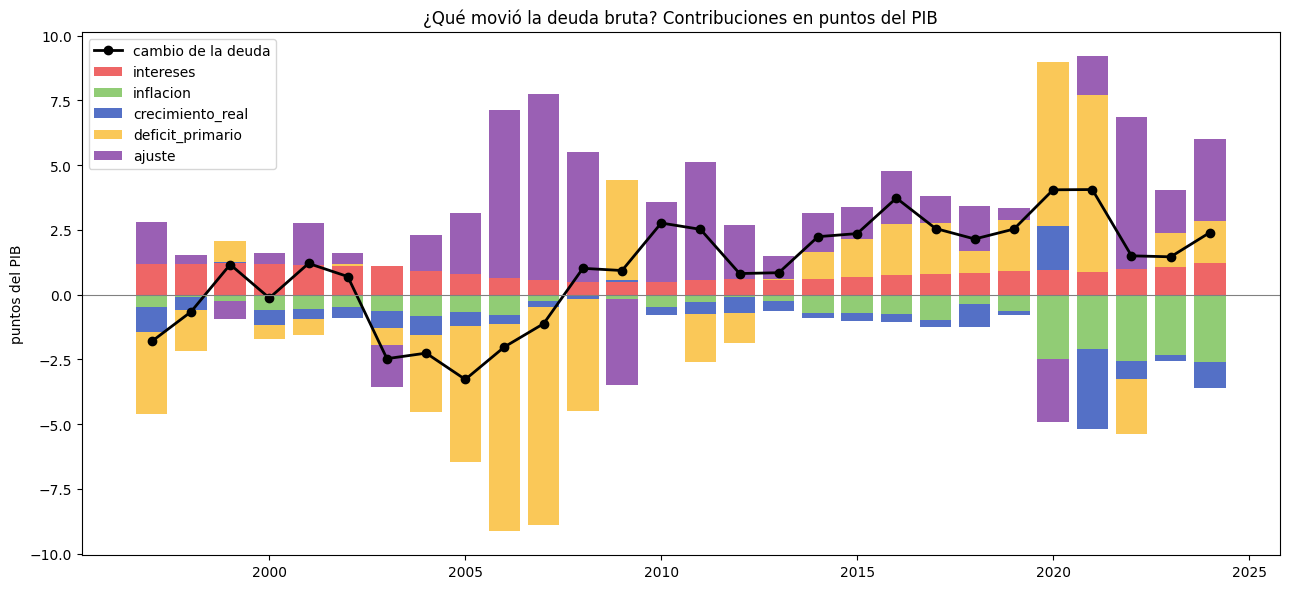

In [7]:
# Celda 7 — Gráfico de barras apiladas: la contribución de cada factor por año,
# con una línea negra para el cambio total de la deuda.

fig, ax = plt.subplots(figsize=(13, 6))
colores = {
    "intereses": "#ee6666", "inflacion": "#91cc75", "crecimiento_real": "#5470c6",
    "deficit_primario": "#fac858", "ajuste": "#9a60b4",
}
positivo = np.zeros(len(dinamica))
negativo = np.zeros(len(dinamica))
for col, color in colores.items():
    valores = dinamica[col].to_numpy()
    abajo = np.where(valores >= 0, positivo, negativo)
    ax.bar(dinamica.index, valores, bottom=abajo, color=color, label=col)
    positivo += np.where(valores >= 0, valores, 0)
    negativo += np.where(valores < 0, valores, 0)
ax.plot(dinamica.index, dinamica["cambio_deuda"], "k-o", label="cambio de la deuda", linewidth=2)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("¿Qué movió la deuda bruta? Contribuciones en puntos del PIB")
ax.set_ylabel("puntos del PIB")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

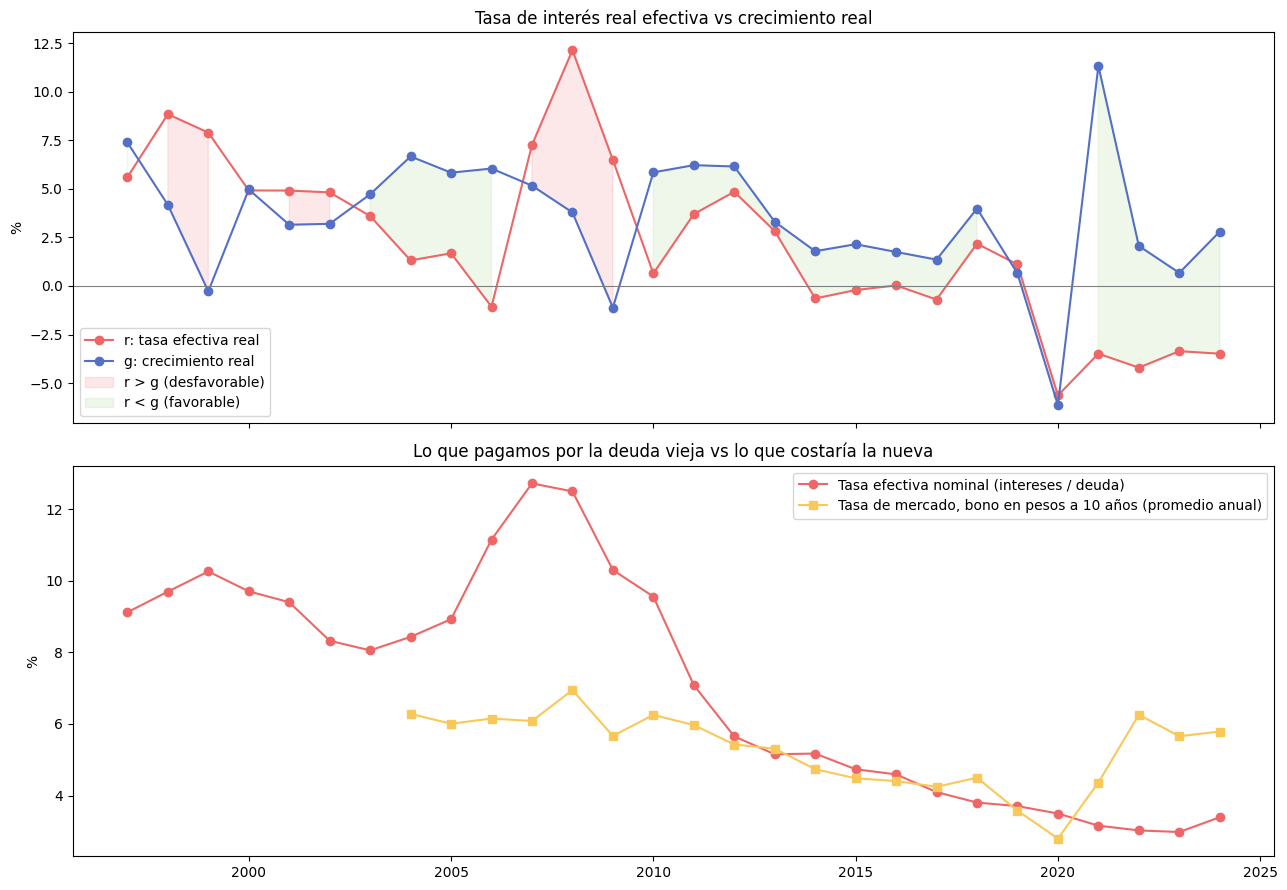

In [8]:
# Celda 8 — Dos gráficos: (1) tasa real efectiva vs crecimiento real, marcando los años r > g y r < g;
# (2) la tasa efectiva que pagamos por la deuda vieja vs la tasa de mercado del bono en pesos a 10 años.

tasa_mercado_10a = pd.DataFrame(
    TasaInteresMercado.objects.serie(InstrumentoTasa.BONO_PESOS, 10)
)
tasa_mercado_10a["anio"] = pd.to_datetime(tasa_mercado_10a["fecha"]).dt.year
tasa_mercado_10a = tasa_mercado_10a.groupby("anio")["valor"].apply(lambda v: v.astype(float).mean())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

ax1.plot(dinamica.index, dinamica["tasa_efectiva_real"], "-o", color="#ee6666", label="r: tasa efectiva real")
ax1.plot(dinamica.index, dinamica["crecimiento_real_pct"], "-o", color="#5470c6", label="g: crecimiento real")
ax1.fill_between(dinamica.index, dinamica["tasa_efectiva_real"], dinamica["crecimiento_real_pct"],
                 where=dinamica["r_menos_g"] > 0, color="#ee6666", alpha=0.15, label="r > g (desfavorable)")
ax1.fill_between(dinamica.index, dinamica["tasa_efectiva_real"], dinamica["crecimiento_real_pct"],
                 where=dinamica["r_menos_g"] <= 0, color="#91cc75", alpha=0.15, label="r < g (favorable)")
ax1.axhline(0, color="gray", linewidth=0.8)
ax1.set_title("Tasa de interés real efectiva vs crecimiento real")
ax1.set_ylabel("%")
ax1.legend()

ax2.plot(dinamica.index, dinamica["tasa_efectiva_nominal"], "-o", color="#ee6666",
         label="Tasa efectiva nominal (intereses / deuda)")
ax2.plot(tasa_mercado_10a.loc[1997:2024].index, tasa_mercado_10a.loc[1997:2024], "-s", color="#fac858",
         label="Tasa de mercado, bono en pesos a 10 años (promedio anual)")
ax2.set_title("Lo que pagamos por la deuda vieja vs lo que costaría la nueva")
ax2.set_ylabel("%")
ax2.legend()

plt.tight_layout()
plt.show()

In [9]:
# Celda 9 — Lista los conceptos de la DIPRES del bloque de financiamiento (activos y pasivos financieros),
# para encontrar el nombre exacto de la "adquisición neta de activos financieros" y usarla en el ajuste.
conceptos = (
    EstadoOperacionesGobiernoCentral.objects
    .filter(unidad=UnidadEstadoOperaciones.PCT_PIB, anio=2024)
    .order_by("orden")
    .values("orden", "nivel", "concepto", "valor")
)
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(conceptos).query("orden >= 30")

,orden,nivel,concepto,valor
29,30,2,ADQUISICION NETA DE ACTIVOS FINANCIEROS > Títulos y valores > Venta de activos financieros,1.392845
30,31,1,ADQUISICION NETA DE ACTIVOS FINANCIEROS > Operaciones de cambio,0.008777
31,32,1,ADQUISICION NETA DE ACTIVOS FINANCIEROS > Caja,0.208018
32,33,1,ADQUISICION NETA DE ACTIVOS FINANCIEROS > Fondos Especiales,0.000000
33,34,2,ADQUISICION NETA DE ACTIVOS FINANCIEROS > Fondos Especiales > Giros,0.000000
34,35,2,ADQUISICION NETA DE ACTIVOS FINANCIEROS > Fondos Especiales > Depósitos,0.000000
35,36,1,ADQUISICION NETA DE ACTIVOS FINANCIEROS > Fondos Especiales: Ajustes por Rezagos y Transferencias,0.000000
36,37,1,ADQUISICION NETA DE ACTIVOS FINANCIEROS > Anticipo de gastos,0.000000
37,38,0,PASIVOS NETOS INCURRIDOS,2.571650
38,39,1,PASIVOS NETOS INCURRIDOS > Endeudamiento Externo Neto,1.048675


In [10]:
# Celda 10 — Divide el "ajuste" en tres partes usando el financiamiento de la DIPRES:
# (1) activos financieros (ahorro/desahorro del Fisco), (2) bono de reconocimiento (pasivo DIPRES
# que no está en la deuda de Hacienda) y (3) valoración (dólar, UF, bonos bajo la par, calendario).
# Comprueba que las tres partes sumen exactamente el ajuste de la celda 5.
PASIVOS = "PASIVOS NETOS INCURRIDOS"
PASIVOS_EXTERNOS = f"{PASIVOS} > Endeudamiento Externo Neto"
PASIVOS_INTERNOS = f"{PASIVOS} > Endeudamiento Interno Neto"
BONO_RECONOCIMIENTO = f"{PASIVOS} > Bono de Reconocimiento"


def serie_dipres_completa(concepto):
    """Serie nominal de la DIPRES alineada con los años de la tabla base; años sin dato = 0."""
    serie = serie_dipres(concepto).reindex(base.index)
    faltantes = serie.isna().sum()
    if faltantes:
        print(f"Aviso: {concepto} no tiene dato en {faltantes} años (se usan como 0)")
    return serie.fillna(0)


pasivos_total = serie_dipres_completa(PASIVOS)
pasivos_deuda = serie_dipres_completa(PASIVOS_EXTERNOS) + serie_dipres_completa(PASIVOS_INTERNOS)
bono_reconocimiento = serie_dipres_completa(BONO_RECONOCIMIENTO)

# Préstamo neto (balance) = activos financieros - pasivos  =>  activos = balance + pasivos
activos_financieros = base["balance"] + pasivos_total
valoracion = base["deuda"].diff() - pasivos_deuda

pib = base["pib_nominal"]
dinamica["aj_activos_financieros"] = (activos_financieros / pib * 100).reindex(dinamica.index)
dinamica["aj_bono_reconocimiento"] = (-bono_reconocimiento / pib * 100).reindex(dinamica.index)
dinamica["aj_valoracion"] = (valoracion / pib * 100).reindex(dinamica.index)

AJUSTES = ["aj_activos_financieros", "aj_bono_reconocimiento", "aj_valoracion"]
diferencia = (dinamica["ajuste"] - dinamica[AJUSTES].sum(axis=1)).abs().max()
print(f"Diferencia máxima entre el ajuste y la suma de sus partes: {diferencia:.6f} puntos del PIB")

dinamica[["ajuste"] + AJUSTES].round(2)

Diferencia máxima entre el ajuste y la suma de sus partes: 0.000000 puntos del PIB


,ajuste,aj_activos_financieros,aj_bono_reconocimiento,aj_valoracion
anio,,,,
1997,1.61,0.94,-0.06,0.73
1998,0.34,-0.91,0.02,1.23
1999,-0.67,-2.54,0.18,1.70
2000,0.42,-1.31,0.25,1.48
2001,1.61,-0.74,0.40,1.96
2002,0.41,-1.61,0.35,1.66
2003,-1.64,-0.32,0.50,-1.81
2004,1.36,1.31,0.57,-0.52
2005,2.36,1.79,0.61,-0.04


,ajuste,aj_activos_financieros,aj_bono_reconocimiento,aj_valoracion
1997-2007 desendeudamiento,19.4,8.6,4.1,6.7
2008-2012 crisis y rebote,11.5,5.8,3.4,2.3
2013-2019 bajo crecimiento,8.9,-0.2,2.9,6.2
2020-2024 pandemia y después,9.8,-2.3,0.6,11.4
1997-2024 total,49.6,11.9,11.1,26.6


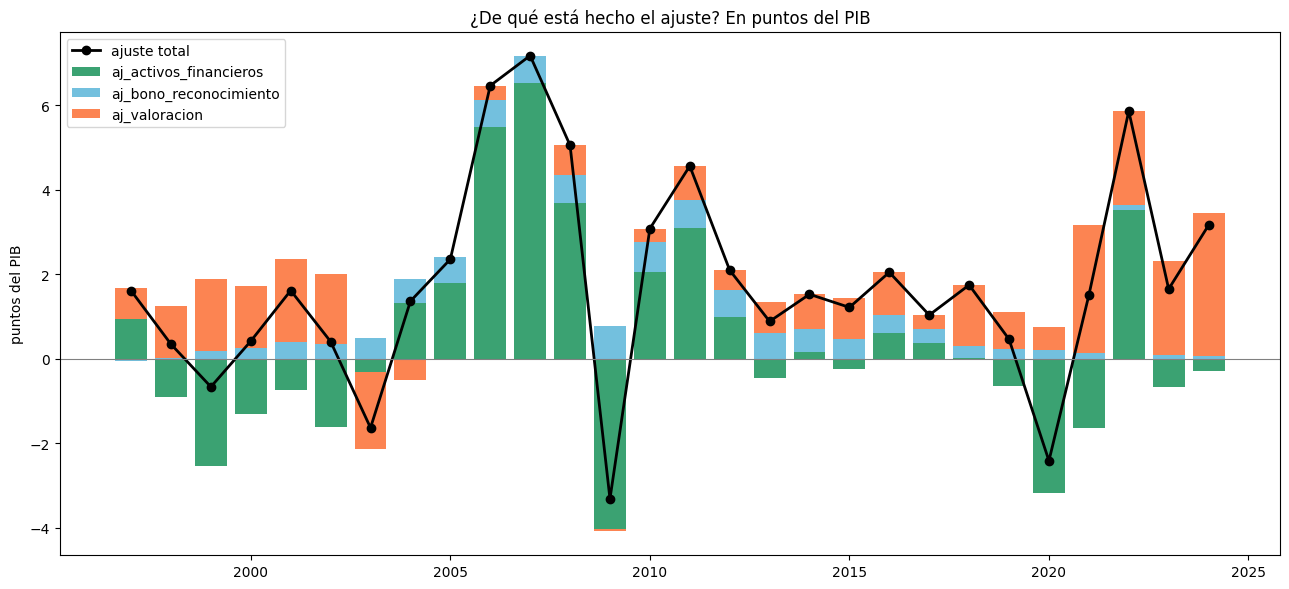

In [11]:
# Celda 11 — Suma las tres partes del ajuste por etapas históricas y grafica, año a año,
# cuánto aportó cada una (barras apiladas) junto al ajuste total (línea negra).
acumulado_ajuste = pd.DataFrame({
    nombre: dinamica.loc[desde:hasta, ["ajuste"] + AJUSTES].sum()
    for nombre, (desde, hasta) in ETAPAS.items()
}).T.round(1)
display(acumulado_ajuste)

fig, ax = plt.subplots(figsize=(13, 6))
colores_ajuste = {
    "aj_activos_financieros": "#3ba272",
    "aj_bono_reconocimiento": "#73c0de",
    "aj_valoracion": "#fc8452",
}
positivo = np.zeros(len(dinamica))
negativo = np.zeros(len(dinamica))
for col, color in colores_ajuste.items():
    valores = dinamica[col].to_numpy()
    abajo = np.where(valores >= 0, positivo, negativo)
    ax.bar(dinamica.index, valores, bottom=abajo, color=color, label=col)
    positivo += np.where(valores >= 0, valores, 0)
    negativo += np.where(valores < 0, valores, 0)
ax.plot(dinamica.index, dinamica["ajuste"], "k-o", label="ajuste total", linewidth=2)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("¿De qué está hecho el ajuste? En puntos del PIB")
ax.set_ylabel("puntos del PIB")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [12]:
# Celda 12 — Inspección: busca los modelos de composición de deuda, muestra sus campos
# y algunas filas de ejemplo, para saber cómo leer la deuda por moneda (pesos, UF, dólares, euros).
from django.apps import apps

for modelo in apps.get_app_config("data_engine").get_models():
    if "composicion" in modelo.__name__.lower():
        print("=" * 80)
        print("Modelo:", modelo.__name__, "| filas:", modelo.objects.count())
        print("Campos:", [f.name for f in modelo._meta.get_fields() if f.concrete])
        display(pd.DataFrame(modelo.objects.order_by("-pk").values()[:8]))

Modelo: ComposicionDeudaMoneda | filas: 189
Campos: ['id', 'anio', 'fecha_corte', 'categoria', 'monto_millones', 'es_corte_parcial', 'fuente', 'fecha_carga']


,id,anio,fecha_corte,categoria,monto_millones,es_corte_parcial,fuente,fecha_carga
0,189,2025,2025-09-30,otras,0.000000,True,hacienda_composicion_deuda,2026-09-10 17:20:02.577350+00:00
1,188,2025,2025-09-30,marco_aleman,0.000000,True,hacienda_composicion_deuda,2026-09-10 17:20:02.576860+00:00
2,187,2025,2025-09-30,euros,18589.400018,True,hacienda_composicion_deuda,2026-09-10 17:20:02.574857+00:00
3,186,2025,2025-09-30,yen_japones,0.000000,True,hacienda_composicion_deuda,2026-09-10 17:20:02.573857+00:00
4,185,2025,2025-09-30,unidad_canasta_birf,0.000000,True,hacienda_composicion_deuda,2026-09-10 17:20:02.572853+00:00
5,184,2025,2025-09-30,unidad_cuenta_bid,0.000000,True,hacienda_composicion_deuda,2026-09-10 17:20:02.571640+00:00
6,183,2025,2025-09-30,pesos,54286.936261,True,hacienda_composicion_deuda,2026-09-10 17:20:02.570640+00:00
7,182,2025,2025-09-30,uf,42724.649056,True,hacienda_composicion_deuda,2026-09-10 17:20:02.569640+00:00


Modelo: ComposicionDeudaAcreedor | filas: 168
Campos: ['id', 'anio', 'fecha_corte', 'categoria', 'monto_millones', 'es_corte_parcial', 'fuente', 'fecha_carga']


,id,anio,fecha_corte,categoria,monto_millones,es_corte_parcial,fuente,fecha_carga
0,168,2025,2025-09-30,otros,41.710049,True,hacienda_composicion_deuda,2026-09-10 17:20:02.796541+00:00
1,167,2025,2025-09-30,aid,0.000000,True,hacienda_composicion_deuda,2026-09-10 17:20:02.795542+00:00
2,166,2025,2025-09-30,bancoestado_chile,4.055488,True,hacienda_composicion_deuda,2026-09-10 17:20:02.794542+00:00
3,165,2025,2025-09-30,eximbank_japon,0.000000,True,hacienda_composicion_deuda,2026-09-10 17:20:02.792027+00:00
4,164,2025,2025-09-30,bonos,146224.900426,True,hacienda_composicion_deuda,2026-09-10 17:20:02.791026+00:00
5,163,2025,2025-09-30,bid,2740.299186,True,hacienda_composicion_deuda,2026-09-10 17:20:02.790025+00:00
6,162,2025,2025-09-30,birf,171.158152,True,hacienda_composicion_deuda,2026-09-10 17:20:02.789026+00:00
7,161,2025,2025-09-30,banco_central_chile,0.000000,True,hacienda_composicion_deuda,2026-09-10 17:20:02.787021+00:00


Modelo: ComposicionDeudaLegislacion | filas: 42
Campos: ['id', 'anio', 'fecha_corte', 'categoria', 'monto_millones', 'es_corte_parcial', 'fuente', 'fecha_carga']


,id,anio,fecha_corte,categoria,monto_millones,es_corte_parcial,fuente,fecha_carga
0,42,2025,2025-09-30,deuda_externa,52462.656949,True,hacienda_composicion_deuda,2026-09-10 17:20:02.878717+00:00
1,41,2025,2025-09-30,deuda_interna,96719.466353,True,hacienda_composicion_deuda,2026-09-10 17:20:02.876710+00:00
2,40,2024,2024-12-31,deuda_externa,47690.543870,False,hacienda_composicion_deuda,2026-09-10 17:20:02.875195+00:00
3,39,2024,2024-12-31,deuda_interna,83134.626696,False,hacienda_composicion_deuda,2026-09-10 17:20:02.873195+00:00
4,38,2023,2023-12-31,deuda_externa,44972.000000,False,hacienda_composicion_deuda,2026-09-10 17:20:02.872197+00:00
5,37,2023,2023-12-31,deuda_interna,80617.000000,False,hacienda_composicion_deuda,2026-09-10 17:20:02.870199+00:00
6,36,2022,2022-12-31,deuda_externa,41167.000000,False,hacienda_composicion_deuda,2026-09-10 17:20:02.869196+00:00
7,35,2022,2022-12-31,deuda_interna,74854.000000,False,hacienda_composicion_deuda,2026-09-10 17:20:02.867179+00:00


In [13]:
# Celda 13 — Arma la deuda por moneda al cierre de cada año (2005-2024) a partir de la composición
# de Hacienda (millones de USD), la convierte a pesos y a su moneda original con el dólar, el euro y la UF
# de cierre, y controla que el total calce con la deuda bruta en dólares de la serie histórica.
from data_engine.models import ComposicionDeudaMoneda, IndicadorEconomico
from data_engine.models.indicador_economico import Indicador

comp = pd.DataFrame(
    ComposicionDeudaMoneda.objects.filter(es_corte_parcial=False)
    .values("anio", "fecha_corte", "categoria", "monto_millones")
)
comp["monto_millones"] = comp["monto_millones"].astype(float)
print("Categorías:", sorted(comp["categoria"].unique()))

# pesos, uf y euros por nombre; el resto (dólares y monedas menores) se trata como dólar
comp["grupo"] = comp["categoria"].map({"pesos": "pesos", "uf": "uf", "euros": "euros"}).fillna("dolares")
por_moneda_usd = comp.pivot_table(index="anio", columns="grupo", values="monto_millones", aggfunc="sum")
fechas_corte = comp.groupby("anio")["fecha_corte"].first()


def valor_cierre(indicador, fecha):
    registro = IndicadorEconomico.objects.valor_al(indicador, fecha)
    return float(registro.valor)


cierre = pd.DataFrame({
    "dolar": [valor_cierre(Indicador.DOLAR, f) for f in fechas_corte],
    "euro": [valor_cierre(Indicador.EURO, f) for f in fechas_corte],
    "uf": [valor_cierre(Indicador.UF, f) for f in fechas_corte],
}, index=fechas_corte.index)

# Control: total de la composición vs deuda bruta en dólares de la serie histórica
bruta_usd = deuda_cruda[
    _contiene(deuda_cruda["tipo_deuda"], "brut")
    & _contiene(deuda_cruda["moneda"], "usd")
    & ~deuda_cruda["es_corte_parcial"]
].set_index("anio")["monto_millones"].astype(float)
control_comp = pd.DataFrame({
    "composicion_total": por_moneda_usd.sum(axis=1),
    "serie_historica_usd": bruta_usd.reindex(por_moneda_usd.index),
})
control_comp["dif_pct"] = (control_comp["composicion_total"] / control_comp["serie_historica_usd"] - 1) * 100
display(control_comp.round(1))

# Participación de cada moneda en la deuda (para tener una idea de la exposición)
display((por_moneda_usd.div(por_moneda_usd.sum(axis=1), axis=0) * 100).round(1))

Categorías: ['dolares_usa', 'euros', 'marco_aleman', 'otras', 'pesos', 'uf', 'unidad_canasta_birf', 'unidad_cuenta_bid', 'yen_japones']


,composicion_total,serie_historica_usd,dif_pct
anio,,,
2005,9371.3,9373.0,-0.0
2006,7666.5,7666.0,0.0
2007,7094.0,7094.0,-0.0
2008,7335.0,7335.0,0.0
2009,11096.6,11096.0,0.0
2010,20357.9,20358.0,-0.0
2011,25927.6,25928.0,-0.0
2012,32422.9,32423.0,-0.0
2013,33514.8,33515.0,-0.0


grupo,dolares,euros,pesos,uf
anio,,,,
2005,70.7,1.0,0.0,28.3
2006,66.4,1.5,0.0,32.1
2007,49.8,1.8,4.8,43.6
2008,38.5,1.5,8.0,52.0
2009,21.9,0.9,13.9,63.3
2010,16.8,0.5,15.0,67.8
2011,16.8,0.3,18.4,64.4
2012,15.9,0.3,19.2,64.6
2013,12.7,0.3,21.2,65.9


In [14]:
# Celda 14 — Separa la valoración (2006-2024) en: efecto dólar, efecto euro, efecto reajuste UF y residuo.
# Cada efecto = deuda en esa moneda al inicio del año × cuánto subió su valor en pesos durante el año,
# en % del PIB. El residuo incluye bonos emitidos bajo/sobre la par, desfases de calendario e imprecisiones.
dolar_ant = cierre["dolar"].shift(1)

# Deuda al inicio del año, en su moneda original
dolares_ini = por_moneda_usd["dolares"].shift(1)                                   # millones de USD
euros_ini = (por_moneda_usd["euros"] * cierre["dolar"] / cierre["euro"]).shift(1)  # millones de EUR
uf_ini_pesos = (por_moneda_usd["uf"] * cierre["dolar"]).shift(1)                   # millones de pesos

efectos_pesos = pd.DataFrame({
    "ef_dolar": dolares_ini * (cierre["dolar"] - dolar_ant),
    "ef_euro": euros_ini * (cierre["euro"] - cierre["euro"].shift(1)),
    "ef_uf": uf_ini_pesos * (cierre["uf"] / cierre["uf"].shift(1) - 1),
}).loc[2006:2024]

EFECTOS = ["ef_dolar", "ef_euro", "ef_uf"]
valoracion_sep = (efectos_pesos.div(base["pib_nominal"].loc[2006:2024], axis=0) * 100)
valoracion_sep.insert(0, "aj_valoracion", dinamica.loc[2006:2024, "aj_valoracion"])
valoracion_sep["residuo"] = valoracion_sep["aj_valoracion"] - valoracion_sep[EFECTOS].sum(axis=1)

# Contexto: cuánto se movieron el dólar y la UF cada año
valoracion_sep["var_dolar_pct"] = (cierre["dolar"] / dolar_ant - 1).loc[2006:2024] * 100
valoracion_sep["var_uf_pct"] = (cierre["uf"] / cierre["uf"].shift(1) - 1).loc[2006:2024] * 100

display(valoracion_sep.round(2))

ETAPAS_VAL = {
    "2006-2012": (2006, 2012),
    "2013-2019": (2013, 2019),
    "2020-2024": (2020, 2024),
    "2006-2024 total": (2006, 2024),
}
display(pd.DataFrame({
    nombre: valoracion_sep.loc[desde:hasta, ["aj_valoracion"] + EFECTOS + ["residuo"]].sum()
    for nombre, (desde, hasta) in ETAPAS_VAL.items()
}).T.round(1))

,aj_valoracion,ef_dolar,ef_euro,ef_uf,residuo,var_dolar_pct,var_uf_pct
anio,,,,,,,
2006,0.34,0.16,0.01,0.03,0.14,3.93,2.01
2007,0.00,-0.22,0.00,0.10,0.11,-7.22,7.01
2008,0.70,0.50,0.01,0.15,0.03,26.88,9.33
2009,-0.05,-0.36,-0.01,-0.06,0.38,-19.50,-2.38
2010,0.33,-0.08,-0.01,0.08,0.34,-7.52,2.45
2011,0.82,0.15,0.00,0.21,0.46,11.34,3.91
2012,0.47,-0.14,-0.00,0.16,0.45,-8.22,2.45
2013,0.74,0.17,0.00,0.15,0.41,9.44,2.05
2014,0.82,0.24,0.00,0.44,0.14,15.97,5.65


,aj_valoracion,ef_dolar,ef_euro,ef_uf,residuo
2006-2012,2.6,0.0,0.0,0.7,1.9
2013-2019,6.2,0.9,0.2,1.9,3.1
2020-2024,11.4,1.9,0.7,3.2,5.6
2006-2024 total,20.2,2.9,0.9,5.8,10.6


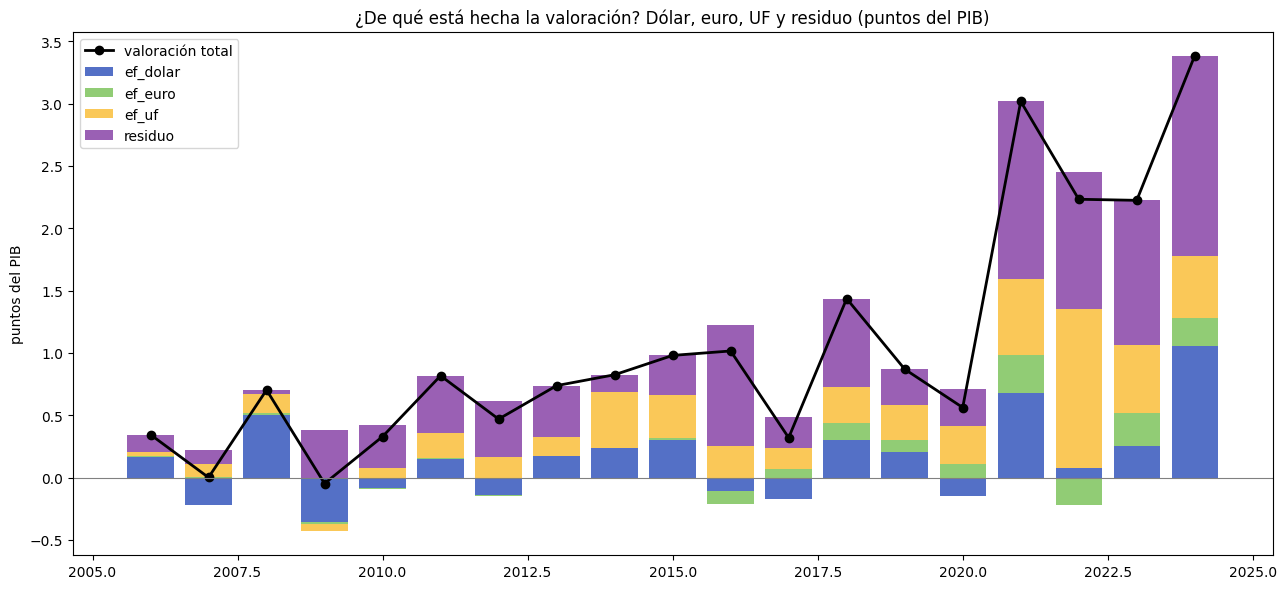

In [15]:
# Celda 15 — Gráfico de barras apiladas: cuánto aportó cada año el dólar, el euro, la UF y el residuo
# a la valoración de la deuda (puntos del PIB), con la valoración total como línea negra.
fig, ax = plt.subplots(figsize=(13, 6))
colores_val = {"ef_dolar": "#5470c6", "ef_euro": "#91cc75", "ef_uf": "#fac858", "residuo": "#9a60b4"}
positivo = np.zeros(len(valoracion_sep))
negativo = np.zeros(len(valoracion_sep))
for col, color in colores_val.items():
    valores = valoracion_sep[col].to_numpy()
    abajo = np.where(valores >= 0, positivo, negativo)
    ax.bar(valoracion_sep.index, valores, bottom=abajo, color=color, label=col)
    positivo += np.where(valores >= 0, valores, 0)
    negativo += np.where(valores < 0, valores, 0)
ax.plot(valoracion_sep.index, valoracion_sep["aj_valoracion"], "k-o", label="valoración total", linewidth=2)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("¿De qué está hecha la valoración? Dólar, euro, UF y residuo (puntos del PIB)")
ax.set_ylabel("puntos del PIB")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [15]:
# Celda 16 — Control de cobertura: ¿BonoLocal tiene todas las colocaciones?
# Suma el monto colocado por año y tipo (BTP en millones de pesos, BTU en miles de UF -> pesos con la UF
# de mitad de año) y lo compara con el endeudamiento interno en bonos que registra la DIPRES.
from datetime import date
from data_engine.models import BonoLocal

bonos = pd.DataFrame(BonoLocal.objects.values())
print("Columnas de BonoLocal:", list(bonos.columns))

col_tipo = next(c for c in bonos.columns if "tipo" in c.lower())
print("Columna de tipo usada:", col_tipo, "| valores:", bonos[col_tipo].unique())

bonos["monto"] = bonos["monto_colocado"].fillna(bonos["monto_emitido"]).astype(float)
uf_mitad_anio = {
    anio: valor_cierre(Indicador.UF, date(anio, 6, 30)) for anio in bonos["anio"].dropna().unique()
}


def monto_en_millones_de_pesos(fila):
    tipo = str(fila[col_tipo]).lower()
    if tipo == "btu":
        return fila["monto"] * 1000 * uf_mitad_anio[fila["anio"]] / 1e6   # miles de UF -> millones de pesos
    return fila["monto"]                                                  # BTP (y Letras, por confirmar)


bonos["monto_mm_pesos"] = bonos.apply(monto_en_millones_de_pesos, axis=1)

colocado = bonos.pivot_table(index="anio", columns=col_tipo, values="monto_mm_pesos", aggfunc="sum").fillna(0)
colocado.columns = [f"colocado_{c}" for c in colocado.columns]
dipres_bonos_internos = serie_dipres(f"{PASIVOS_INTERNOS} > Endeudamiento > Bonos")

cobertura = colocado.join(dipres_bonos_internos.rename("dipres_bonos_internos"), how="outer").loc[2000:2025]
cobertura["total_bonolocal_sin_letras"] = cobertura[[c for c in cobertura.columns
                                                    if c.startswith("colocado_") and "letra" not in c]].sum(axis=1)
cobertura["cobertura_pct"] = cobertura["total_bonolocal_sin_letras"] / cobertura["dipres_bonos_internos"] * 100
(cobertura / [1e6 if c != "cobertura_pct" else 1 for c in cobertura.columns]).round(2)   # billones de pesos, salvo el %

Columnas de BonoLocal: ['id', 'nombre_bono', 'anio', 'fecha_emision', 'fecha_vencimiento', 'es_reapertura', 'tipo_instrumento', 'madurez_anios', 'monto_emitido', 'monto_colocado', 'tasa_caratula', 'paga_intereses_raw', 'status', 'fuente', 'fecha_carga']
Columna de tipo usada: tipo_instrumento | valores: ['btu' 'btp' 'letra']


,colocado_btp,colocado_btu,colocado_letra,dipres_bonos_internos,total_bonolocal_sin_letras,cobertura_pct
2000,NaN,NaN,NaN,0.00,0.00,NaN
2001,NaN,NaN,NaN,0.00,0.00,NaN
2002,NaN,NaN,NaN,0.00,0.00,NaN
2003,0.00,0.22,0.00,0.21,0.22,106.95
2004,0.00,0.43,0.00,0.45,0.43,95.43
2005,0.00,0.38,0.00,0.36,0.38,107.91
2006,NaN,NaN,NaN,0.00,0.00,NaN
2007,0.17,0.20,0.00,0.36,0.37,104.43
2008,0.20,0.76,0.00,0.92,0.96,104.87
2009,0.41,1.22,0.00,1.64,1.63,99.78


In [16]:
# Celda 17 — Calcula el precio aproximado de cada colocación local (BTP, BTU y Letras) con su cupón
# y la tasa de mercado de ese año y plazo, y el descuento = (100 - precio) × monto colocado.
# Suma los descuentos por año, los pasa a % del PIB y los compara con el residuo de la valoración.
TASAS_POR_TIPO = {"btp": InstrumentoTasa.BONO_PESOS, "letra": InstrumentoTasa.BONO_PESOS,
                  "btu": InstrumentoTasa.BONO_UF}

# Curvas de tasas de mercado: promedio anual por instrumento y plazo
tasas = pd.DataFrame(
    TasaInteresMercado.objects
    .filter(instrumento__in=[InstrumentoTasa.BONO_PESOS, InstrumentoTasa.BONO_UF])
    .values("fecha", "instrumento", "plazo_anios", "valor")
)
tasas["anio"] = pd.to_datetime(tasas["fecha"]).dt.year
tasas["valor"] = tasas["valor"].astype(float)
curvas = tasas.groupby(["instrumento", "anio", "plazo_anios"])["valor"].mean()


def tasa_mercado(instrumento, anio, plazo):
    """Tasa de mercado de ese año interpolada al plazo pedido (plana fuera del rango de plazos)."""
    try:
        curva = curvas.loc[(instrumento, anio)]
    except KeyError:
        return np.nan
    return float(np.interp(plazo, curva.index.to_numpy(), curva.to_numpy()))


def precio_bono(cupon_pct, tasa_pct, anios):
    """Precio por cada 100 de carátula, cupones semestrales. Cupón 0 = bono cupón cero."""
    c, y, m = cupon_pct / 100, tasa_pct / 100, max(anios, 0) * 2
    if m == 0:
        return 100.0
    descuento = (1 + y / 2) ** (-m)
    if abs(y) < 1e-12:
        return 100 * (c / 2 * m + 1)
    return 100 * ((c / 2) / (y / 2) * (1 - descuento) + descuento)


col = bonos.copy()
col["tipo"] = col["tipo_instrumento"].astype(str).str.lower()
col["cupon"] = col["tasa_caratula"].astype(float).fillna(0)
col.loc[col["tipo"] == "letra", "cupon"] = 0.0
col["plazo_residual"] = [
    (pd.Timestamp(v) - pd.Timestamp(date(int(a), 7, 1))).days / 365.25
    for v, a in zip(col["fecha_vencimiento"], col["anio"])
]
col["tasa_mercado"] = [
    tasa_mercado(TASAS_POR_TIPO[t], int(a), p)
    for t, a, p in zip(col["tipo"], col["anio"], col["plazo_residual"])
]
col["precio"] = [
    precio_bono(c, y, p) if pd.notna(y) else np.nan
    for c, y, p in zip(col["cupon"], col["tasa_mercado"], col["plazo_residual"])
]
col["descuento_mm_pesos"] = (1 - col["precio"] / 100) * col["monto_mm_pesos"]

sin_tasa = col["tasa_mercado"].isna().sum()
print(f"Colocaciones sin tasa de mercado para su año (no se valoran): {sin_tasa}")

display(
    col[["nombre_bono", "anio", "tipo", "es_reapertura", "cupon", "plazo_residual",
         "tasa_mercado", "precio", "monto_mm_pesos", "descuento_mm_pesos"]]
    .sort_values("descuento_mm_pesos", ascending=False).head(15).round(2)
)

# Descuento por año, separado en reaperturas, emisiones nuevas y cupón cero, en % del PIB
col["clase"] = np.where(col["cupon"] == 0, "cupon_cero",
                        np.where(col["es_reapertura"], "reapertura", "nueva"))
desc_anual = (col.pivot_table(index="anio", columns="clase", values="descuento_mm_pesos", aggfunc="sum")
              .reindex(range(2006, 2025)).fillna(0))
desc_anual_pct = desc_anual.div(base["pib_nominal"].loc[2006:2024], axis=0) * 100
desc_anual_pct.columns = [f"desc_{c}" for c in desc_anual_pct.columns]

comparacion = desc_anual_pct.copy()
comparacion["desc_total"] = comparacion.sum(axis=1)
comparacion["residuo"] = valoracion_sep["residuo"]
comparacion["sin_explicar"] = comparacion["residuo"] - comparacion["desc_total"]
comparacion["cobertura_pct"] = cobertura["cobertura_pct"].reindex(comparacion.index)
comparacion.loc[2021, "cobertura_pct"] = (
    (cobertura.loc[2021, "total_bonolocal_sin_letras"] + cobertura.loc[2021, "colocado_letra"])
    / cobertura.loc[2021, "dipres_bonos_internos"] * 100
)
comparacion["cobertura_ok"] = comparacion["cobertura_pct"].between(85, 115)
display(comparacion.round(2))

ok = comparacion["cobertura_ok"]
print("Años con buena cobertura:  residuo", round(comparacion.loc[ok, "residuo"].sum(), 2),
      "| descuento calculado", round(comparacion.loc[ok, "desc_total"].sum(), 2))
print("Años con cobertura baja:   residuo", round(comparacion.loc[~ok, "residuo"].sum(), 2),
      "| descuento calculado", round(comparacion.loc[~ok, "desc_total"].sum(), 2))

# Para el paso siguiente (bonos externos): ver qué columnas tiene BonoExterno
from data_engine.models import BonoExterno
print("Columnas de BonoExterno:", [f.name for f in BonoExterno._meta.get_fields() if f.concrete])

Colocaciones sin tasa de mercado para su año (no se valoran): 0


,nombre_bono,anio,tipo,es_reapertura,cupon,plazo_residual,tasa_mercado,precio,monto_mm_pesos,descuento_mm_pesos
116,BTU0001033 (UF),2022,btu,False,0.0,11.25,2.08,79.21,1414461.98,294054.83
127,BTU0001033,2023,btu,False,0.0,10.25,2.28,79.26,917755.48,190308.70
136,BTP0000527,2024,btp,False,0.0,2.84,5.31,86.14,775000.00,107399.70
137,BTP0000429,2024,btp,False,0.0,4.75,5.51,77.23,450000.00,102471.92
161,BTU0001028,2025,btu,True,0.0,3.25,1.81,94.31,1786651.68,101719.42
156,BTP0000527,2025,btp,True,0.0,1.85,4.68,91.82,1200000.00,98192.92
115,BTU0001028 (UF),2022,btu,False,0.0,6.25,1.91,88.78,827832.49,92923.30
111,BTU-2033 (UF),2021,btu,False,0.0,12.25,1.36,84.67,561515.79,86058.57
124,BTP0000724,2023,btp,False,0.0,1.04,6.48,93.58,1200000.00,77087.72
126,BTP0510750,2023,btp,False,5.1,27.04,5.66,92.35,851000.00,65117.94


,desc_cupon_cero,desc_nueva,desc_reapertura,desc_total,residuo,sin_explicar,cobertura_pct,cobertura_ok
anio,,,,,,,,
2006,0.00,0.00,0.00,0.00,0.14,0.14,NaN,False
2007,0.00,0.01,0.00,0.01,0.11,0.11,104.43,True
2008,0.00,0.08,0.00,0.08,0.03,-0.04,104.87,True
2009,0.00,-0.01,0.00,-0.01,0.38,0.39,99.78,True
2010,0.00,0.06,0.00,0.06,0.34,0.28,101.25,True
2011,0.00,-0.02,0.00,-0.02,0.46,0.48,98.68,True
2012,0.00,-0.06,0.00,-0.06,0.45,0.51,95.34,True
2013,0.00,-0.09,-0.01,-0.09,0.41,0.51,92.57,True
2014,0.00,-0.29,0.00,-0.29,0.14,0.43,86.46,True


Años con buena cobertura:  residuo 6.62 | descuento calculado -0.74
Años con cobertura baja:   residuo 3.97 | descuento calculado -0.52
Columnas de BonoExterno: ['id', 'nombre_bono', 'fecha_emision', 'fecha_vencimiento', 'es_reapertura', 'moneda', 'monto', 'tasa_caratula_raw', 'tasa_caratula_fija', 'tasa_bono_tesoro', 'tasa_local_tesoro_chile', 'precio', 'yield_emision', 'spread_caratula', 'spread_nota_referencia', 'pago_intereses', 'vigencia', 'fuente', 'fecha_carga']


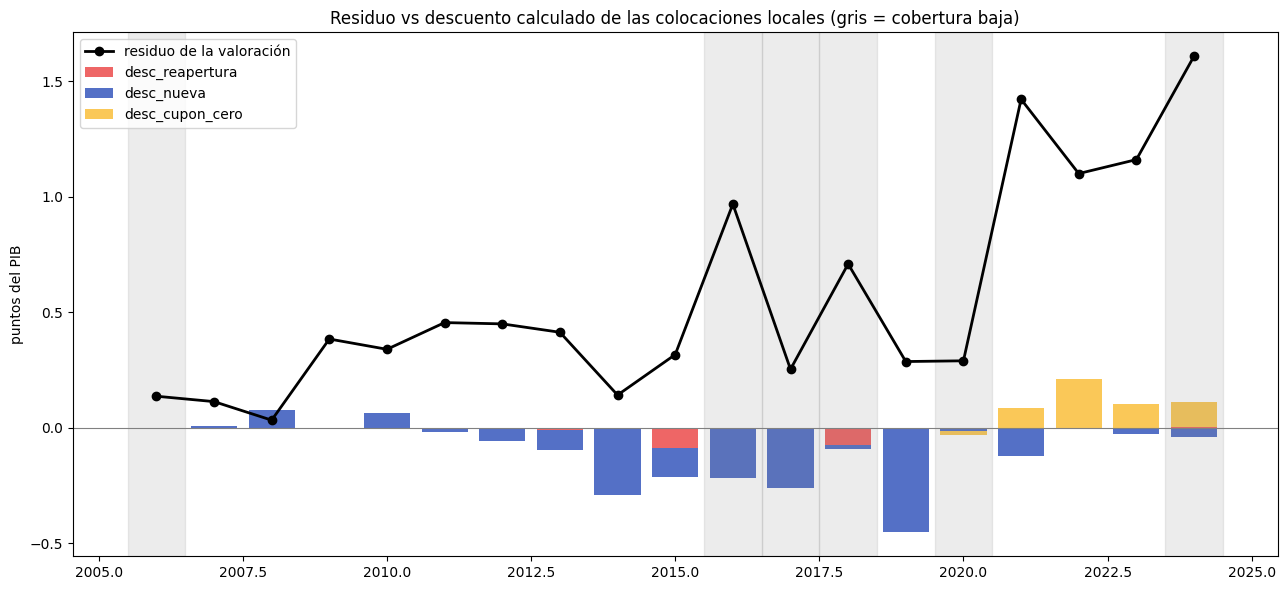

In [17]:
# Celda 18 — Compara año a año el residuo de la valoración (línea negra) con el descuento calculado
# de las colocaciones locales (barras: reaperturas, emisiones nuevas, cupón cero).
# Los años con cobertura baja de BonoLocal se marcan con fondo gris.
fig, ax = plt.subplots(figsize=(13, 6))
colores_desc = {"desc_reapertura": "#ee6666", "desc_nueva": "#5470c6", "desc_cupon_cero": "#fac858"}
positivo = np.zeros(len(comparacion))
negativo = np.zeros(len(comparacion))
for c, color in colores_desc.items():
    if c not in comparacion:
        continue
    valores = comparacion[c].to_numpy()
    abajo = np.where(valores >= 0, positivo, negativo)
    ax.bar(comparacion.index, valores, bottom=abajo, color=color, label=c)
    positivo += np.where(valores >= 0, valores, 0)
    negativo += np.where(valores < 0, valores, 0)
ax.plot(comparacion.index, comparacion["residuo"], "k-o", linewidth=2, label="residuo de la valoración")
for anio in comparacion.index[~comparacion["cobertura_ok"]]:
    ax.axvspan(anio - 0.5, anio + 0.5, color="gray", alpha=0.15)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Residuo vs descuento calculado de las colocaciones locales (gris = cobertura baja)")
ax.set_ylabel("puntos del PIB")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [18]:
# Celda 19 — Calcula el descuento de cada colocación externa: (100 - precio de emisión) × monto,
# convertido a pesos con el dólar o euro del día de emisión. Usa el precio real de BonoExterno y,
# si falta, lo calcula con el cupón y el yield de emisión. Controla la cobertura contra la DIPRES
# y suma el resultado a la comparación con el residuo.
ext = pd.DataFrame(BonoExterno.objects.values(
    "nombre_bono", "fecha_emision", "fecha_vencimiento", "es_reapertura", "moneda",
    "monto", "tasa_caratula_fija", "yield_emision", "precio",
))
for c in ["monto", "tasa_caratula_fija", "yield_emision", "precio"]:
    ext[c] = ext[c].astype(float)
ext["moneda"] = ext["moneda"].astype(str).str.lower()
ext["anio"] = pd.to_datetime(ext["fecha_emision"]).dt.year

# Escala del precio: si viene como 0,985 en vez de 98,5, se lleva a base 100
if ext["precio"].median() < 2:
    ext["precio"] = ext["precio"] * 100
    print("Precio venía en base 1: se llevó a base 100")

# Precio faltante: se calcula con cupón y yield de emisión
ext["plazo"] = (pd.to_datetime(ext["fecha_vencimiento"]) - pd.to_datetime(ext["fecha_emision"])).dt.days / 365.25
faltante = ext["precio"].isna() & ext["tasa_caratula_fija"].notna() & ext["yield_emision"].notna()
ext.loc[faltante, "precio"] = [
    precio_bono(c, y, p)
    for c, y, p in zip(ext.loc[faltante, "tasa_caratula_fija"], ext.loc[faltante, "yield_emision"],
                       ext.loc[faltante, "plazo"])
]
print(f"Precios calculados con cupón y yield: {faltante.sum()} | sin precio posible: {ext['precio'].isna().sum()}")

# Monto en millones de pesos con el tipo de cambio del día de emisión
INDICADOR_MONEDA = {"usd": Indicador.DOLAR, "eur": Indicador.EURO}
ext["tipo_cambio"] = [
    valor_cierre(INDICADOR_MONEDA[m], f) if m in INDICADOR_MONEDA else 1.0
    for m, f in zip(ext["moneda"], ext["fecha_emision"])
]
ext["monto_mm_pesos"] = ext["monto"] * ext["tipo_cambio"]
ext["descuento_mm_pesos"] = (1 - ext["precio"] / 100) * ext["monto_mm_pesos"]

# Control de cobertura vs DIPRES (endeudamiento externo en bonos), en billones de pesos
dipres_bonos_externos = serie_dipres(f"{PASIVOS_EXTERNOS} > Endeudamiento > Bonos")
cobertura_ext = pd.DataFrame({
    "bonoexterno": ext.groupby("anio")["monto_mm_pesos"].sum(),
    "dipres_bonos_externos": dipres_bonos_externos,
}).loc[2006:2025]
cobertura_ext["cobertura_pct"] = cobertura_ext["bonoexterno"] / cobertura_ext["dipres_bonos_externos"] * 100
display((cobertura_ext / [1e6, 1e6, 1]).round(2))

# Colocaciones con más descuento (para revisar que tengan sentido)
display(
    ext[["nombre_bono", "anio", "moneda", "es_reapertura", "tasa_caratula_fija", "yield_emision",
         "precio", "monto", "monto_mm_pesos", "descuento_mm_pesos"]]
    .sort_values("descuento_mm_pesos", ascending=False).head(12).round(2)
)

# Sumar a la comparación con el residuo
desc_ext_pct = (ext.groupby("anio")["descuento_mm_pesos"].sum()
                .reindex(range(2006, 2025)).fillna(0)
                / base["pib_nominal"].loc[2006:2024] * 100)
comparacion["desc_externo"] = desc_ext_pct
comparacion["desc_total_con_ext"] = comparacion["desc_total"] + comparacion["desc_externo"]
comparacion["sin_explicar_con_ext"] = comparacion["residuo"] - comparacion["desc_total_con_ext"]
display(comparacion[["residuo", "desc_total", "desc_externo", "desc_total_con_ext",
                     "sin_explicar_con_ext", "cobertura_ok"]].round(2))

print("Total 2006-2024:  residuo", round(comparacion["residuo"].sum(), 2),
      "| descuento local", round(comparacion["desc_total"].sum(), 2),
      "| descuento externo", round(comparacion["desc_externo"].sum(), 2))

Precios calculados con cupón y yield: 0 | sin precio posible: 0


,bonoexterno,dipres_bonos_externos,cobertura_pct
2006,NaN,0.00,NaN
2007,NaN,0.00,NaN
2008,NaN,0.00,NaN
2009,NaN,0.00,NaN
2010,0.82,0.80,102.03
2011,0.27,0.66,40.46
2012,0.67,0.70,94.77
2013,NaN,0.00,NaN
2014,1.79,1.25,143.91
2015,1.10,0.91,120.52


,nombre_bono,anio,moneda,es_reapertura,tasa_caratula_fija,yield_emision,precio,monto,monto_mm_pesos,descuento_mm_pesos
37,Global 2041 en USD,2021,usd,False,3.10,3.30,97.06,1700.0,1200693.00,35300.37
17,Global 2026 en USD,2016,usd,False,3.12,3.41,97.63,1349.0,983717.78,23343.62
18,Global 2026 en Euro,2016,eur,False,1.75,1.97,98.06,1200.0,951024.00,18487.91
32,Global 2051 en Euro,2021,eur,False,1.25,1.30,98.81,1250.0,1086162.50,12881.89
44,Global 2027 en USD,2022,usd,False,0.10,0.30,98.93,1500.0,1198290.00,12797.74
38,Global 2037 en USD,2025,usd,False,4.95,5.74,99.24,1600.0,1614720.00,12271.87
16,Global 2030 en Euro,2015,eur,False,1.88,2.02,98.13,950.0,633080.00,11857.59
25,Global 2040 en Euro,2020,eur,False,1.25,1.30,99.14,1269.0,1101111.30,9447.53
47,Global 2042 en USD,2022,usd,False,4.34,4.35,99.43,2000.0,1606540.00,9221.54
50,Global 2034 en Euro,2023,eur,False,4.12,4.22,99.21,1176.0,1031551.92,8128.63


,residuo,desc_total,desc_externo,desc_total_con_ext,sin_explicar_con_ext,cobertura_ok
anio,,,,,,
2006,0.14,0.00,0.00,0.00,0.14,False
2007,0.11,0.01,0.00,0.01,0.11,True
2008,0.03,0.08,0.00,0.08,-0.04,True
2009,0.38,-0.01,0.00,-0.01,0.39,True
2010,0.34,0.06,-0.01,0.05,0.29,True
2011,0.46,-0.02,0.00,-0.02,0.47,True
2012,0.45,-0.06,0.01,-0.05,0.50,True
2013,0.41,-0.09,0.00,-0.09,0.51,True
2014,0.14,-0.29,-0.00,-0.29,0.43,True


Total 2006-2024:  residuo 10.59 | descuento local -1.26 | descuento externo 0.02


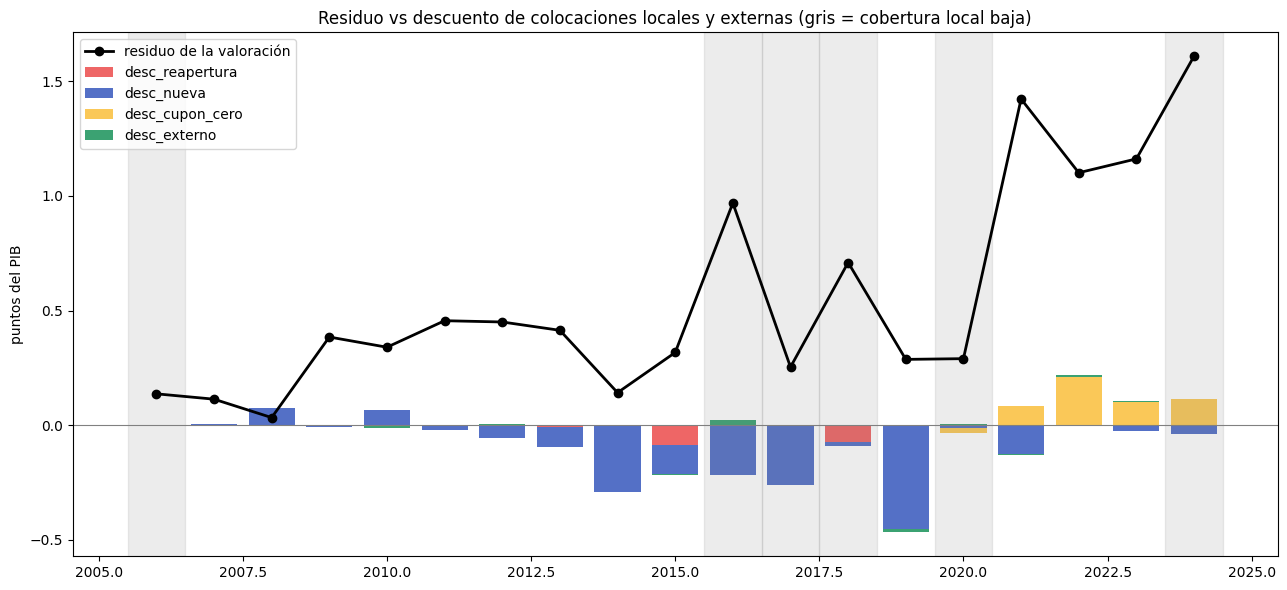

In [19]:
# Celda 20 — Igual que la celda 18, pero agregando el descuento de las colocaciones externas
# (barras verdes) junto a las locales, contra el residuo de la valoración.
fig, ax = plt.subplots(figsize=(13, 6))
colores_desc2 = {"desc_reapertura": "#ee6666", "desc_nueva": "#5470c6",
                 "desc_cupon_cero": "#fac858", "desc_externo": "#3ba272"}
positivo = np.zeros(len(comparacion))
negativo = np.zeros(len(comparacion))
for c, color in colores_desc2.items():
    if c not in comparacion:
        continue
    valores = comparacion[c].fillna(0).to_numpy()
    abajo = np.where(valores >= 0, positivo, negativo)
    ax.bar(comparacion.index, valores, bottom=abajo, color=color, label=c)
    positivo += np.where(valores >= 0, valores, 0)
    negativo += np.where(valores < 0, valores, 0)
ax.plot(comparacion.index, comparacion["residuo"], "k-o", linewidth=2, label="residuo de la valoración")
for anio in comparacion.index[~comparacion["cobertura_ok"]]:
    ax.axvspan(anio - 0.5, anio + 0.5, color="gray", alpha=0.15)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Residuo vs descuento de colocaciones locales y externas (gris = cobertura local baja)")
ax.set_ylabel("puntos del PIB")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [20]:
# Celda 21 — Control de completitud (1): compara el stock de bonos vigentes al 31-dic-2024 en nuestras
# tablas (BonoLocal + BonoExterno) con el stock oficial de bonos del Cuadro I.7.2 del IFP 4T24 (DIPRES).
# Vigente = colocado hasta 2024 y con vencimiento posterior al corte. Montos en billones de pesos.
CORTE = date(2024, 12, 31)
uf_corte = valor_cierre(Indicador.UF, CORTE)
dolar_corte = valor_cierre(Indicador.DOLAR, CORTE)
euro_corte = valor_cierre(Indicador.EURO, CORTE)

# Cifras oficiales: IFP 4T24, Cuadro I.7.2 (bonos, millones de USD) y tipo de cambio usado por la DIPRES
OFICIAL_BONOS_USD = {"interna": 83130.7, "externa": 44629.4}
DOLAR_DIPRES_2024 = 992.12

# Bonos locales vigentes al corte, valorados a la UF del corte
loc = bonos.copy()
loc["tipo"] = loc["tipo_instrumento"].astype(str).str.lower()
loc["venc"] = pd.to_datetime(loc["fecha_vencimiento"]).dt.date
vig_loc = loc[(loc["anio"] <= CORTE.year) & (loc["venc"] > CORTE)].copy()
vig_loc["mm_pesos_corte"] = np.where(
    vig_loc["tipo"] == "btu", vig_loc["monto"] * 1000 * uf_corte / 1e6, vig_loc["monto"]
)

# Bonos externos vigentes al corte, valorados al dólar/euro del corte
FX_CORTE = {"usd": dolar_corte, "eur": euro_corte}
e = ext.copy()
e["venc"] = pd.to_datetime(e["fecha_vencimiento"]).dt.date
vig_ext = e[(e["anio"] <= CORTE.year) & (e["venc"] > CORTE)].copy()
vig_ext["mm_pesos_corte"] = vig_ext["monto"] * vig_ext["moneda"].map(FX_CORTE).fillna(1.0)

stock = pd.DataFrame({
    "nuestro": [vig_loc["mm_pesos_corte"].sum() / 1e6, vig_ext["mm_pesos_corte"].sum() / 1e6],
    "oficial": [OFICIAL_BONOS_USD["interna"] * DOLAR_DIPRES_2024 / 1e6,
                OFICIAL_BONOS_USD["externa"] * DOLAR_DIPRES_2024 / 1e6],
}, index=["bonos internos", "bonos externos"])
stock.loc["total"] = stock.sum()
stock["diferencia"] = stock["nuestro"] - stock["oficial"]
stock["cobertura_pct"] = stock["nuestro"] / stock["oficial"] * 100
print(f"UF al corte: {uf_corte:,.2f} | dólar: {dolar_corte:,.2f} | euro: {euro_corte:,.2f}")
display(stock.round(2))

# Detalle de lo nuestro por tipo y moneda, para ver dónde está la diferencia
display((vig_loc.groupby("tipo")["mm_pesos_corte"].sum() / 1e6).round(2).rename("locales, billones"))
display((vig_ext.groupby("moneda")["mm_pesos_corte"].sum() / 1e6).round(2).rename("externos, billones"))

# Posibles duplicados: mismo vencimiento y año de colocación con nombres distintos
loc["nombre_base"] = loc["nombre_bono"].str.replace(r"\s*\(.*\)\s*$", "", regex=True).str.strip()
dup = loc[loc.duplicated(["nombre_base", "anio", "venc"], keep=False)].sort_values(["nombre_base", "anio"])
print(f"Filas locales con posible duplicado (mismo nombre base, año y vencimiento): {len(dup)}")
display(dup[["nombre_bono", "anio", "tipo", "venc", "monto"]].head(20))

UF al corte: 38,416.69 | dólar: 992.12 | euro: 1,033.57


,nuestro,oficial,diferencia,cobertura_pct
bonos internos,71.55,82.48,-10.93,86.75
bonos externos,38.73,44.28,-5.55,87.47
total,110.28,126.75,-16.47,87.00


tipo
btp    34.31
btu    37.24
Name: locales, billones, dtype: float64

moneda
eur    11.44
usd    27.29
Name: externos, billones, dtype: float64

Filas locales con posible duplicado (mismo nombre base, año y vencimiento): 0


,nombre_bono,anio,tipo,venc,monto


,interna_nuestro,interna_oficial,externa_nuestro,externa_oficial,dif_interna,dif_externa
2025,3.60,3.27,2.55,2.00,0.34,0.55
2026,4.35,4.97,2.58,1.60,-0.62,0.98
2027,1.77,4.18,1.49,2.37,-2.40,-0.88
2028,5.74,7.47,1.98,3.33,-1.73,-1.34
2029,2.66,5.66,2.54,1.70,-2.99,0.85
2030,10.50,8.87,1.71,2.82,1.63,-1.12
2031,0.00,0.00,3.76,3.05,0.00,0.71
2032,1.49,0.01,1.49,1.25,1.48,0.24
2033,9.24,7.32,0.00,1.74,1.93,-1.74
2034,4.14,2.02,2.70,2.19,2.13,0.51


Suma 2025-2035 (billones):


interna_nuestro    49.42
interna_oficial    52.32
externa_nuestro    20.81
externa_oficial    22.13
dtype: float64

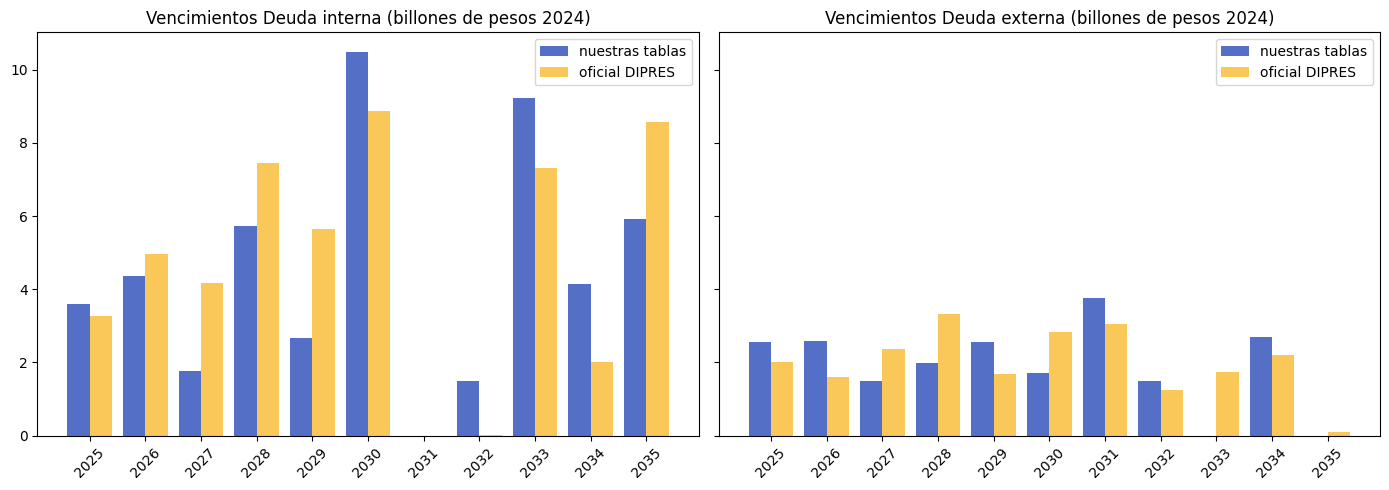

In [21]:
# Celda 22 — Control de completitud (2): compara los vencimientos de nuestros bonos vigentes (2025-2035)
# con el perfil oficial de amortizaciones del Cuadro I.7.4 del IFP 4T24 (millones de pesos 2024).
# La deuda externa oficial incluye créditos BID/BIRF (no son bonos): esperamos estar algo por debajo.
OFICIAL_VENCIMIENTOS = pd.DataFrame({
    "interna": [3267466, 4972258, 4175476, 7465587, 5657280, 8866387, 0, 7891, 7315398, 2018769, 8577709],
    "externa": [2004391, 1599638, 2372978, 3327098, 1695705, 2823729, 3050009, 1246335, 1740686, 2189052, 83979],
}, index=range(2025, 2036)) / 1e6   # billones de pesos

nuestro_venc = pd.DataFrame({
    "interna": vig_loc.groupby(pd.to_datetime(vig_loc["fecha_vencimiento"]).dt.year)["mm_pesos_corte"].sum(),
    "externa": vig_ext.groupby(pd.to_datetime(vig_ext["fecha_vencimiento"]).dt.year)["mm_pesos_corte"].sum(),
}).reindex(range(2025, 2036)).fillna(0) / 1e6

calendario = pd.DataFrame({
    "interna_nuestro": nuestro_venc["interna"],
    "interna_oficial": OFICIAL_VENCIMIENTOS["interna"],
    "externa_nuestro": nuestro_venc["externa"],
    "externa_oficial": OFICIAL_VENCIMIENTOS["externa"],
})
calendario["dif_interna"] = calendario["interna_nuestro"] - calendario["interna_oficial"]
calendario["dif_externa"] = calendario["externa_nuestro"] - calendario["externa_oficial"]
display(calendario.round(2))
print("Suma 2025-2035 (billones):")
display(calendario[["interna_nuestro", "interna_oficial", "externa_nuestro", "externa_oficial"]].sum().round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
x = np.arange(len(calendario))
for ax, col, titulo in [(ax1, "interna", "Deuda interna"), (ax2, "externa", "Deuda externa")]:
    ax.bar(x - 0.2, calendario[f"{col}_nuestro"], width=0.4, color="#5470c6", label="nuestras tablas")
    ax.bar(x + 0.2, calendario[f"{col}_oficial"], width=0.4, color="#fac858", label="oficial DIPRES")
    ax.set_xticks(x)
    ax.set_xticklabels(calendario.index, rotation=45)
    ax.set_title(f"Vencimientos {titulo} (billones de pesos 2024)")
    ax.legend()
plt.tight_layout()
plt.show()

In [22]:
# Celda 23 — Lista los bonos internos que nuestras tablas tienen venciendo en 2030 y 2032-2034
# (años donde tenemos más que el calendario oficial), para buscar si fueron canjeados o prepagados.
sobrantes = vig_loc[pd.to_datetime(vig_loc["fecha_vencimiento"]).dt.year.isin([2030, 2032, 2033, 2034])]
display(
    sobrantes.groupby(["nombre_bono", "tipo", "venc"])
    .agg(colocaciones=("anio", lambda a: sorted(a)), billones=("mm_pesos_corte", lambda m: m.sum() / 1e6))
    .round(2)
    .sort_values("venc")
)

,,,colocaciones,billones
nombre_bono,tipo,venc,,
BTU-20 (UF),btu,2030-01-01,[2010],0.46
BTU-20 (UF) Reapertura,btu,2030-01-01,[2010],0.69
BTU-20 (UF) Reapertura,btu,2030-01-01,[2011],0.65
BTU-2030 (UF),btu,2030-09-01,[2018],0.76
BTU-2030 Reap. (UF),btu,2030-09-01,[2019],1.45
BTU-2030 (Reap.) (UF),btu,2030-09-01,[2021],1.24
BTU0190930,btu,2030-09-01,[2024],0.75
BTP0470930 ($),btp,2030-09-01,[2022],0.01
BTU0190930 (UF),btu,2030-09-01,[2023],0.18


In [23]:
# Celda 24 — Guarda los números del residuo (deuda no explicada) para calibrarlo en el motor de deuda:
# promedio y dispersión por período, en puntos del PIB por año. Usa valoracion_sep de la celda 14.
residuo = valoracion_sep["residuo"]
calibracion = pd.DataFrame({
    "promedio": [residuo.loc[2006:2020].mean(), residuo.loc[2021:2024].mean(), residuo.mean()],
    "desv_estandar": [residuo.loc[2006:2020].std(), residuo.loc[2021:2024].std(), residuo.std()],
    "minimo": [residuo.loc[2006:2020].min(), residuo.loc[2021:2024].min(), residuo.min()],
    "maximo": [residuo.loc[2006:2020].max(), residuo.loc[2021:2024].max(), residuo.max()],
    "anios": [15, 4, 19],
}, index=["2006-2020 (normal)", "2021-2024 (tasas altas)", "2006-2024 (total)"])
calibracion.round(2)

,promedio,desv_estandar,minimo,maximo,anios
2006-2020 (normal),0.35,0.24,0.03,0.97,15
2021-2024 (tasas altas),1.32,0.24,1.10,1.61,4
2006-2024 (total),0.56,0.47,0.03,1.61,19


## Conclusiones del notebook 002 — Dinámica de la deuda (1997–2024)

**Validación:** la descomposición calza con las fuentes oficiales: deuda/PIB vs Hacienda (diferencias de décimas),
intereses/PIB vs DIPRES (exacto), ajuste total vs IFP 4T24 Cuadro I.7.1 (3,16% del PIB en 2024 y 1,65% en 2023,
exacto), efecto dólar + UF vs "Corrección Monetaria y de Monedas" del Cuadro I.7.3 (1,77% vs 1,80% del PIB en 2024).

**Qué movió la deuda bruta (+27,2 pp del PIB entre 1996 y 2024):** intereses +24,0; inflación −23,1;
crecimiento real −12,7; balance primario −10,6; ajuste +49,6.

**De qué está hecho el ajuste (+49,6):**
- Activos financieros (ahorro/desahorro: FEES, FRP, capitalizaciones, préstamos): +11,9
- Bono de reconocimiento (transición de pensiones de 1981): +11,1
- Dólar, euro y UF (2006–2024): +9,6 (dólar 2,9; euro 0,9; UF 5,8)
- Valoración 1997–2005 sin separar (probablemente tipo de cambio): +6,4
- Residuo 2006–2024: +10,6 (~22,6 billones de pesos, ~17% del stock de 2024)

**El residuo:** es la diferencia entre carátula y caja en las operaciones de deuda (comprobado al decimal
en 2024: 1,61% del PIB = endeudamiento neto a carátula 13,10 vs en caja 8,09 billones).
Principal hipótesis: recompras e intercambios de deuda (programa de 2024: recompra de bonos "no benchmark"
a cambio de Letras a 2027 y 2029 y BTU a 2028). Descartado: emisión bajo la par en las licitaciones normales
(locales −1,3; externos +0,0). Los swaps explicarían a lo más ~0,2% del PIB en un año extremo.

**Para el motor de deuda:**
- El ahorro y desahorro del Estado es una variable de la estrategia, no algo que se estime.
- La deuda se lleva por moneda (pesos, UF, dólares, euros); el dólar y la UF salen solos de la simulación.
- El bono de reconocimiento se deja en ~0.
- El residuo se calibra con la celda 24 y se prueba con análisis de sensibilidad (0 / 0,5 / 1,3 pp por año).
- Calendario de vencimientos: usar el perfil oficial (IFP 4T24, Cuadro I.7.4) hasta corregir BonoLocal y
  BonoExterno, que tienen ~87% del stock oficial y no registran recompras ni intercambios.

**El misterio sigue abierto:**
- ¿Cuánto del residuo explican las recompras e intercambios? (solicitud de transparencia enviada a la DIPRES)
- ¿Por qué el cálculo muestra bonos sobre la par en 2009–2019 si el residuo fue positivo?
- ¿Fue 2016 un gran intercambio? ¿Y 2020?
- ¿Cuántos vencimientos de nuestras tablas son aproximados (1 de enero, nombres "BTU-20")?